# Exercise 12.6 — Random Forest Classification
## Fruit Basket: Majority Voting

**Problem:** Several decision trees classify the same fruit-basket instance. Use majority voting to decide which fruit is most likely to be selected.

In the provided reference figure, Tree-1 predicts **Apple**, Tree-2 predicts **Apple**, and Tree-n predicts **Banana**. Therefore, the majority-voting result is **Apple**.

This notebook demonstrates the exercise directly and then shows how a Random Forest classifier can be trained in Python.

## 1. Majority voting from the reference figure

In [1]:

tree_predictions = ['Apple', 'Apple', 'Banana']

from collections import Counter
votes = Counter(tree_predictions)
print('Votes from each tree:', tree_predictions)
print('\nVote count:')
for fruit, count in votes.items():
    print(f'{fruit}: {count}')

final_prediction = votes.most_common(1)[0][0]
print('\nFinal fruit selected by majority voting:', final_prediction)

Votes from each tree: ['Apple', 'Apple', 'Banana']

Vote count:
Apple: 2
Banana: 1

Final fruit selected by majority voting: Apple


## 2. Visualize the tree votes
The bar chart illustrates the vote count shown in the reference figure.

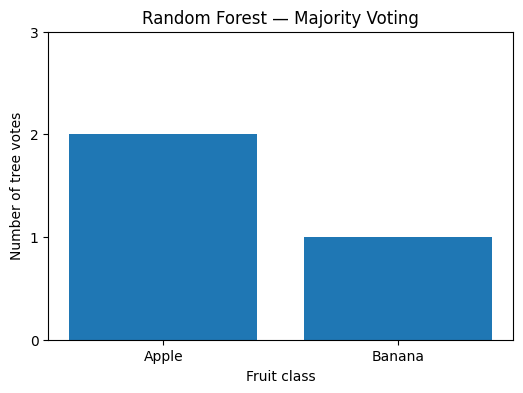

In [2]:
import matplotlib.pyplot as plt
labels = list(votes.keys())
counts = list(votes.values())

plt.figure(figsize=(6, 4))
plt.bar(labels, counts)
plt.xlabel('Fruit class')
plt.ylabel('Number of tree votes')
plt.title('Random Forest — Majority Voting')
plt.yticks(range(0, max(counts) + 2))
plt.show()

## 3. Demonstrate Random Forest with a small sample dataset
The reference figure does not provide numerical fruit measurements, so the dataset below is illustrative. It demonstrates the Random Forest workflow using simple fruit features.

In [3]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

fruit_data = pd.DataFrame({
    'weight_g': [150, 170, 140, 160, 180, 130, 120, 135, 125, 145, 155, 165],
    'sweetness': [7, 8, 6, 7, 8, 6, 9, 8, 9, 7, 8, 7],
    'yellow_score': [1, 1, 0, 0, 1, 0, 9, 8, 9, 8, 0, 1],
    'fruit': ['Apple', 'Apple', 'Apple', 'Apple', 'Apple', 'Apple',
              'Banana', 'Banana', 'Banana', 'Banana', 'Apple', 'Apple']
})
fruit_data

,weight_g,sweetness,yellow_score,fruit
0,150,7,1,Apple
1,170,8,1,Apple
2,140,6,0,Apple
3,160,7,0,Apple
4,180,8,1,Apple
5,130,6,0,Apple
6,120,9,9,Banana
7,135,8,8,Banana
8,125,9,9,Banana
9,145,7,8,Banana


## 4. Train the Random Forest classifier

In [4]:
X = fruit_data[['weight_g', 'sweetness', 'yellow_score']]
y = fruit_data['fruit']

model = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=42)
model.fit(X, y)
print('Random Forest classifier trained successfully.')

Random Forest classifier trained successfully.


## 5. Predict the class of a new fruit instance

In [5]:
new_fruit = pd.DataFrame([{
    'weight_g': 155,
    'sweetness': 7,
    'yellow_score': 0
}])

prediction = model.predict(new_fruit)[0]
individual_tree_votes = [tree.predict(new_fruit)[0] for tree in model.estimators_]
tree_vote_counts = Counter(individual_tree_votes)

print('New fruit features:')
display(new_fruit)
print('Votes from individual trees:')
for fruit, count in tree_vote_counts.items():
    print(f'{fruit}: {count}')
print('\nRandom Forest final prediction:', prediction)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: U

New fruit features:


,weight_g,sweetness,yellow_score
0,155,7,0


Votes from individual trees:
0.0: 95
1.0: 5

Random Forest final prediction: Apple


## Conclusion
- A Random Forest combines predictions from multiple decision trees.
- For classification, the class receiving the most votes is selected.
- In the provided exercise diagram, Apple receives two votes and Banana receives one vote, so the answer is **Apple**.